# Wine Quality: сквозной проход по CRISP-DM

Лабораторная работа №3. Плотников Максим Александрович, магистратура, 3 семестр.

Данные: [Wine Quality, UCI](https://archive.ics.uci.edu/dataset/186/wine+quality) — первоисточник
той же таблицы, что выложена на Kaggle (например,
[red wine quality](https://www.kaggle.com/datasets/uciml/red-wine-quality-cassino-y-axis)).
1599 образцов красного и 4898 белого вина, 11 физико-химических показателей и медианная оценка
дегустационной комиссии по шкале от 3 до 9.

Задача: по результатам лабораторного анализа сказать, попадёт ли вино в категорию
«качественное» (`quality >= 7`), и оценить ожидаемый балл. Ноутбук проходит все шесть фаз
CRISP-DM, фазы подписаны в заголовках разделов.

## Маршрут по фазам

| Фаза CRISP-DM | Раздел | Что получается на выходе |
|---|---|---|
| Понимание бизнеса | 1 | задача, критерии успеха, ограничения |
| Понимание данных | 2 | профиль набора, связи признаков с оценкой |
| Подготовка данных | 3 | очищенная таблица, три новых признака, train/test |
| Моделирование | 4 | baseline, логистическая регрессия, случайный лес, подбор порога |
| Оценка | 5 | метрики на отложенной выборке, проверка критериев, разбор ошибок |
| Развёртывание | 6 | сохранённый пайплайн, функция скоринга, план сопровождения |

Ноутбук выполняется сверху вниз на чистом окружении: данные скачиваются с сервера UCI,
все случайные операции зафиксированы `RANDOM_STATE = 42`.

In [1]:
import json
import ssl
import time
import urllib.request
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
RAW_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print("Корень проекта:", PROJECT_ROOT)

pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1
Корень проекта: E:\учёба\магистратура 3 сем\применение машинного обучения в креативных индустриях\project


## 1. Понимание бизнеса

Винодельня контролирует качество по двум каналам. Анализатор выдаёт числа: спирт, кислоты,
сахар, диоксид серы, плотность, сульфаты, pH. Дегустационная комиссия ставит балл, по которому
вино и оценивают в продаже; в этом наборе балл — медиана оценок как минимум трёх дегустаторов.

Комиссия не может прогнать весь поток партий, а анализатор может. Отсюда рабочая гипотеза:
физико-химический профиль связан с итоговым баллом достаточно сильно, чтобы использовать
модель как фильтр и отправлять на дегустацию в первую очередь перспективные партии.
В ноутбуке проверяем только связь между химией и баллом. Выигрыш дегустации по времени
и стоимости не измеряем: для этого нужны данные винодельни, которых у нас нет.

Задачи машинного обучения:

1. бинарная классификация «качественное / обычное» — фильтр для комиссии;
2. регрессия ожидаемого балла — сортировка партий внутри очереди.

Критерии успеха зафиксированы до моделирования, чтобы потом не подгонять их под результат:

| Критерий | Порог | Откуда порог |
|---|---|---|
| F1 по классу «качественное» | ≥ 0,55 | класс занимает 19% выборки, accuracy здесь обманывает |
| Recall по классу «качественное» | ≥ 0,70 | пропущенное хорошее вино не увидит комиссия; ложная тревога стоит одного лишнего бокала |
| ROC-AUC | ≥ 0,80 | качество ранжирования не зависит от выбранного порога |
| MAE регрессии | ≤ 0,60 балла | половина шага шкалы: партии можно сортировать, не обещая точный балл |

Сравнение идёт с двумя baseline: `DummyClassifier(strategy="prior")` и
`DummyRegressor(strategy="mean")` — это ответ «всегда самый частый класс» и «всегда средний балл».

Ограничения набора: одно хозяйство (Vinho Verde, Португалия), баллы субъективны, нет сорта
винограда, года урожая и условий хранения. Перенос на другое хозяйство потребует проверки.

## 2. Понимание данных

Kaggle отдаёт те же файлы, но требует авторизации, поэтому берём первоисточник UCI:
два CSV с разделителем `;`, по одному на красные и белые вина. Признак типа вина в исходных
файлах отсутствует — добавляем его сами, иначе модель перемешает два разных распределения.

Загрузчик сначала смотрит локальный кэш `data/raw`, затем скачивает файл. Контекст TLS
собирается по бандлу `certifi`, если он установлен: на этой машине системное хранилище
сертификатов отдаёт просроченную цепочку для `archive.ics.uci.edu`.

In [2]:
DATA_URLS = {
    "red": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "white": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
}


def download_csv(url: str) -> pd.DataFrame:
    """Скачивает CSV с сервера UCI и разбирает его как таблицу."""
    try:
        import certifi

        context = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        context = ssl.create_default_context()
    with urllib.request.urlopen(url, context=context, timeout=60) as response:
        return pd.read_csv(BytesIO(response.read()), sep=";")


def load_wine(wine_type: str) -> pd.DataFrame:
    """Читает кэш из data/raw, при его отсутствии скачивает файл."""
    cached = RAW_DIR / f"winequality-{wine_type}.csv"
    if cached.exists():
        frame = pd.read_csv(cached, sep=";")
    else:
        frame = download_csv(DATA_URLS[wine_type])
        frame.to_csv(cached, index=False, sep=";")
    frame["wine_type"] = wine_type
    return frame


raw = pd.concat([load_wine("red"), load_wine("white")], ignore_index=True)
print(f"Строк: {len(raw)}, столбцов: {raw.shape[1]}")
raw.head()

Строк: 6497, столбцов: 13


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
profile = pd.DataFrame(
    {
        "тип": raw.dtypes.astype(str),
        "пропуски": raw.isna().sum(),
        "уникальных": raw.nunique(),
        "минимум": raw.min(numeric_only=True),
        "максимум": raw.max(numeric_only=True),
    }
)
display(profile)
print("Полных дубликатов строк:", raw.duplicated().sum())
raw.describe().T.round(3)

,тип,пропуски,уникальных,минимум,максимум
alcohol,float64,0,111,8.00000,14.90000
chlorides,float64,0,214,0.00900,0.61100
citric acid,float64,0,89,0.00000,1.66000
density,float64,0,998,0.98711,1.03898
fixed acidity,float64,0,106,3.80000,15.90000
free sulfur dioxide,float64,0,135,1.00000,289.00000
pH,float64,0,108,2.72000,4.01000
quality,int64,0,7,3.00000,9.00000
residual sugar,float64,0,316,0.60000,65.80000
sulphates,float64,0,111,0.22000,2.00000


Полных дубликатов строк: 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


Пропусков нет, все признаки числовые, кроме добавленного `wine_type`. Диапазоны широкие:
остаточный сахар доходит до 65,8 г/л, общий диоксид серы — до 440 мг/л, это выбросы белых вин.

Дубликатов 1177 из 6497 строк (18%): 240 у красных и 937 у белых. У лабораторных данных
повторяющаяся строка почти наверняка означает повторный замер того же образца, а не два разных
вина. Оставлять их нельзя: одинаковые векторы попадут и в train, и в test, и метрика станет
оптимистичной. Удаляем на этапе подготовки, а не здесь, чтобы сначала показать масштаб проблемы.

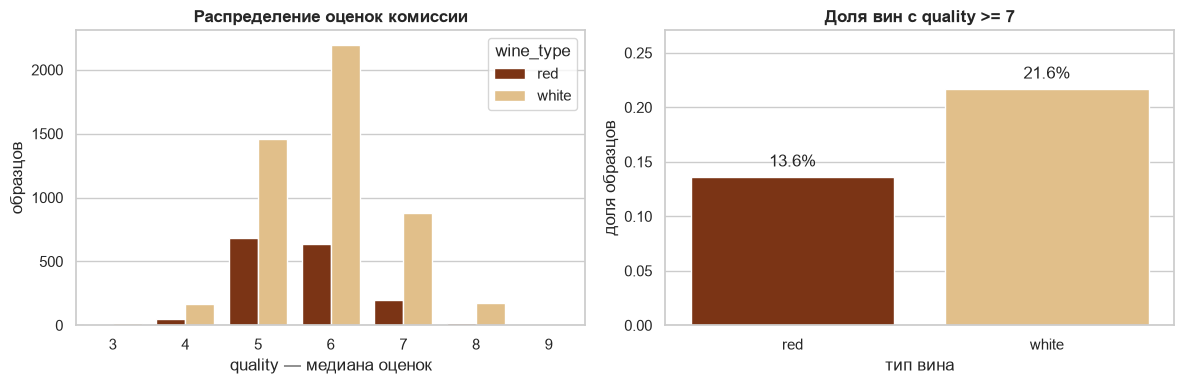

,образцов,доля
quality,,
3,30,0.005
4,216,0.033
5,2138,0.329
6,2836,0.437
7,1079,0.166
8,193,0.030
9,5,0.001
quality >= 7,1277,0.197


In [4]:
quality_counts = raw["quality"].value_counts().sort_index()
good_share = (raw["quality"] >= 7).groupby(raw["wine_type"]).mean().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=raw, x="quality", hue="wine_type", palette=["#8c2d04", "#f0c27b"], ax=axes[0])
axes[0].set_title("Распределение оценок комиссии")
axes[0].set_xlabel("quality — медиана оценок")
axes[0].set_ylabel("образцов")

sns.barplot(
    x=good_share.index,
    y=good_share.values,
    hue=good_share.index,
    palette=["#8c2d04", "#f0c27b"],
    ax=axes[1],
)
legend = axes[1].get_legend()
if legend is not None:
    legend.remove()
axes[1].set_title("Доля вин с quality >= 7")
axes[1].set_ylabel("доля образцов")
axes[1].set_xlabel("тип вина")
axes[1].set_ylim(0, good_share.max() * 1.25)
for position, value in enumerate(good_share.values):
    axes[1].text(position, value + 0.01, f"{value:.1%}", ha="center")
plt.tight_layout()
plt.show()

summary = pd.DataFrame(
    {
        "образцов": quality_counts,
        "доля": (quality_counts / len(raw)).round(3),
    }
)
summary.loc["quality >= 7"] = [int((raw["quality"] >= 7).sum()), round((raw["quality"] >= 7).mean(), 3)]
summary

Оценки — дискретная шкала с центром в 6: она одна даёт 43,7% строк, вместе с 5 — 76,6%.
Категория «качественное» (`>= 7`) — 19,7% набора, причём у белых вин она встречается чаще:
21,6% против 13,6% у красных. Девяток пять штук на весь набор, поэтому отдельный класс из них
не построить: экстремумы останутся только в регрессии.

Порог 7, а не 6, выбран по смыслу шкалы: 6 — типичное вино, 7 и выше — то, что комиссия
рекомендует. Порог 6 превратил бы задачу в предсказание большинства (63% положительных)
и обесценил бы метрики.

Теперь связи. Смотрим корреляции Пирсона, понимая, что они ловят только линейную часть.

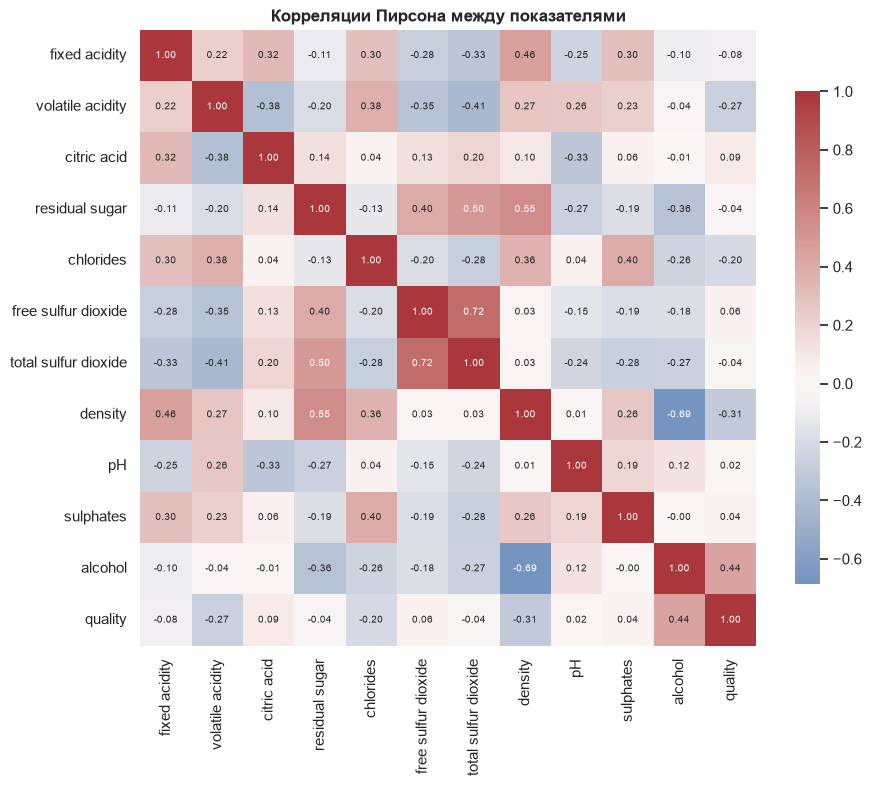

Связь с quality, по убыванию модуля:
alcohol                 0.444
density                -0.306
volatile acidity       -0.266
chlorides              -0.201
citric acid             0.086
fixed acidity          -0.077
free sulfur dioxide     0.055
total sulfur dioxide   -0.041
sulphates               0.038
residual sugar         -0.037
pH                      0.020


In [5]:
numeric_features_raw = [column for column in raw.columns if column != "wine_type"]
correlation = raw[numeric_features_raw].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8},
)
plt.title("Корреляции Пирсона между показателями")
plt.show()

print("Связь с quality, по убыванию модуля:")
print(
    correlation["quality"]
    .drop("quality")
    .reindex(correlation["quality"].drop("quality").abs().sort_values(ascending=False).index)
    .round(3)
    .to_string()
)

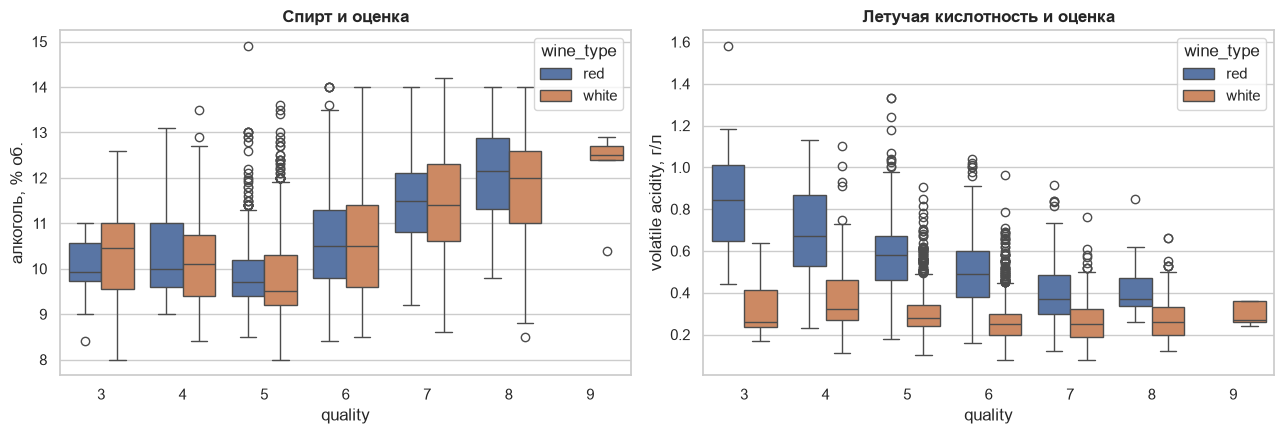

alcohol        volatile acidity        residual sugar        density       
             mean median             mean median           mean median    mean median
wine_type                                                                            
red         10.42   10.2             0.53   0.52           2.54    2.2    1.00   1.00
white       10.51   10.4             0.28   0.26           6.39    5.2    0.99   0.99

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=raw, x="quality", y="alcohol", hue="wine_type", ax=axes[0])
axes[0].set_title("Спирт и оценка")
axes[0].set_xlabel("quality")
axes[0].set_ylabel("алкоголь, % об.")

sns.boxplot(data=raw, x="quality", y="volatile acidity", hue="wine_type", ax=axes[1])
axes[1].set_title("Летучая кислотность и оценка")
axes[1].set_xlabel("quality")
axes[1].set_ylabel("volatile acidity, г/л")

plt.tight_layout()
plt.show()

raw.groupby("wine_type")[["alcohol", "volatile acidity", "residual sugar", "density"]].agg(
    ["mean", "median"]
).round(2)

Что видно:

- спирт связан с оценкой положительно (r = 0,44), плотность (r = −0,31) и летучая кислотность
  (r = −0,27) — отрицательно. Это ожидаемо: спирт и плотность обратны по смыслу, а летучая
  кислотность в высоких концентрациях даёт уксусный тон;
- силы связи умеренные, ни один признак не решает задачу в одиночку;
- красные и белые вина различаются по сахару (2,5 против 6,4 г/л) и плотности, спирт у них
  почти одинаковый. Тип вина поэтому оставляем отдельным признаком, а не шумом;
- часть признаков дублирует друг друга: плотность и спирт связаны с r = −0,67, свободный
  и общий диоксид серы — с r = 0,72. Это пригодится при разборе важности признаков.

Для деревьев мультиколлинеарность не проблема, для логистической регрессии её гасит L2-штраф
по умолчанию.

## 3. Подготовка данных

Правила, которых держимся дальше:

1. Удаляем полные дубликаты — иначе копии строк попадут и в train, и в test.
2. Добавляем три признака с доменным смыслом, а не все комбинации подряд.
3. Делим данные на train и test до любого обучения, со стратификацией по целевому классу.
4. Масштабирование и кодирование живут внутри `Pipeline`. Если отмасштабировать всю таблицу
   заранее, среднее и дисперсия теста попадут в обучение — классическая утечка.
5. `quality` не участвует в признаках ни в каком виде: только как цель.

Новые признаки:

- `total_acidity` = `fixed acidity` + `volatile acidity` — общая кислотность, по ней говорят
  о балансе вина; две кислоты коррелируют слабо, сумма несёт дополнительный смысл;
- `free_so2_ratio` = `free sulfur dioxide` / `total sulfur dioxide` — доля активного
  консерванта: защищает именно свободная часть, общая — резерв;
- `alcohol_density` = `alcohol` / `density` — компактная мера «тела» вина из двух обратно
  связанных переменных.

In [7]:
df = raw.drop_duplicates().reset_index(drop=True).copy()
df["total_acidity"] = df["fixed acidity"] + df["volatile acidity"]
df["free_so2_ratio"] = df["free sulfur dioxide"] / df["total sulfur dioxide"]
df["alcohol_density"] = df["alcohol"] / df["density"]
df["is_quality"] = (df["quality"] >= 7).astype(int)

print(f"После удаления дубликатов: {len(df)} строк (было {len(raw)})")
print(
    "Пропусков:",
    int(df.isna().sum().sum()),
    "| бесконечностей:",
    int(np.isinf(df.select_dtypes("number")).sum().sum()),
)
df[["total_acidity", "free_so2_ratio", "alcohol_density"]].describe().T.round(3)

После удаления дубликатов: 5320 строк (было 6497)
Пропусков: 0 | бесконечностей: 0


,count,mean,std,min,25%,50%,75%,max
total_acidity,5320.0,7.559,1.366,4.110,6.690,7.280,8.080,16.285
free_so2_ratio,5320.0,0.287,0.126,0.023,0.201,0.269,0.350,0.857
alcohol_density,5320.0,10.610,1.215,8.025,9.546,10.446,11.453,14.936


In [8]:
feature_cols = [column for column in df.columns if column not in {"quality", "is_quality"}]
X = df[feature_cols]
y_class = df["is_quality"]
y_score = df["quality"]

X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X,
    y_class,
    y_score,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_class,
)

split_summary = pd.DataFrame(
    {
        "строк": [len(X_train), len(X_test)],
        "доля quality >= 7": [yc_train.mean(), yc_test.mean()],
        "доля красных": [
            (X_train["wine_type"] == "red").mean(),
            (X_test["wine_type"] == "red").mean(),
        ],
    },
    index=["train", "test"],
)
split_summary.round(3)

,строк,доля quality >= 7,доля красных
train,4256,0.19,0.255
test,1064,0.19,0.258


In [9]:
numeric_features = [column for column in feature_cols if column != "wine_type"]
categorical_features = ["wine_type"]


def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    """Кодирует тип вина и, если нужно, масштабирует числовые признаки."""
    numeric_step = ("num", StandardScaler(), numeric_features) if scale_numeric else (
        "num",
        "passthrough",
        numeric_features,
    )
    return ColumnTransformer(
        [
            numeric_step,
            ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_features),
        ]
    )


print("Числовых признаков:", len(numeric_features))
print("Категориальных:", categorical_features)
print("Всего признаков на входе модели:", len(feature_cols))

Числовых признаков: 14
Категориальных: ['wine_type']
Всего признаков на входе модели: 15


Доля качественных вин в train и test совпадает до третьего знака, тип вина распределён
одинаково — стратификация сработала. Дальше все сравнения моделей идут на train через
кросс-валидацию, тест трогаем один раз в разделе оценки.

## 4. Моделирование

Сравниваем три уровня сложности:

- `DummyClassifier` — нижняя граница, показывает, что даёт «всегда большинство»;
- логистическая регрессия — линейная модель, 15 коэффициентов, интерпретируемая;
- случайный лес на 400 деревьев — нелинейности и взаимодействия.

Схема — 5-фолдовая стратифицированная кросс-валидация на train, предсказания собираются
out-of-fold, чтобы каждая строка была предсказана моделью, которая её не видела.

Метрики: F1 по классу «качественное», ROC-AUC и PR-AUC. Accuracy в основную таблицу не ставлю —
при 19% положительных она награждает модель за игнорирование редкого класса. PR-AUC важнее
ROC-AUC, потому что положительный класс редкий.

In [10]:
classifiers = {
    "Dummy (prior)": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=False)),
            ("clf", DummyClassifier(strategy="prior")),
        ]
    ),
    "Логистическая регрессия": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=True)),
            (
                "clf",
                LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
            ),
        ]
    ),
    "Случайный лес": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=False)),
            (
                "clf",
                RandomForestClassifier(
                    n_estimators=400,
                    min_samples_leaf=2,
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_probabilities = {}
rows = []

for name, pipeline in classifiers.items():
    started = time.perf_counter()
    oof = cross_val_predict(
        pipeline, X_train, yc_train, cv=cv, method="predict_proba"
    )[:, 1]
    oof_probabilities[name] = oof
    predicted = (oof >= 0.5).astype(int)
    rows.append(
        {
            "модель": name,
            "F1 (порог 0.5)": f1_score(yc_train, predicted),
            "ROC-AUC": roc_auc_score(yc_train, oof),
            "PR-AUC": average_precision_score(yc_train, oof),
            "секунд на CV": time.perf_counter() - started,
        }
    )

cv_results = pd.DataFrame(rows).set_index("модель").round(3)
cv_results

,F1 (порог 0.5),ROC-AUC,PR-AUC,секунд на CV
модель,,,,
Dummy (prior),0.000,0.499,0.189,0.037
Логистическая регрессия,0.537,0.832,0.515,0.109
Случайный лес,0.507,0.847,0.562,4.331


Baseline получает F1 = 0: он никогда не называет вино качественным, при этом его accuracy 81%.
Это и есть иллюстрация, зачем нужны F1 и recall.

Логистическая регрессия и лес почти не отличаются по ROC-AUC (0,832 против 0,847), лес лучше
по PR-AUC (0,562 против 0,515). Прирост от нелинейности скромный: связь признаков с оценкой
в основном монотонная, что подтверждали корреляции. Разница между моделями небольшая, поэтому
решаю по PR-AUC, где лес выше: для редкого класса это более честная метрика, чем ROC-AUC.

Порог 0,5 для леса с `class_weight="balanced_subsample"` занижен: веса сдвигают вероятности
вверх, и модель осторожничает. Подберём порог по out-of-fold вероятностям на train — тест
в подборе не участвует.

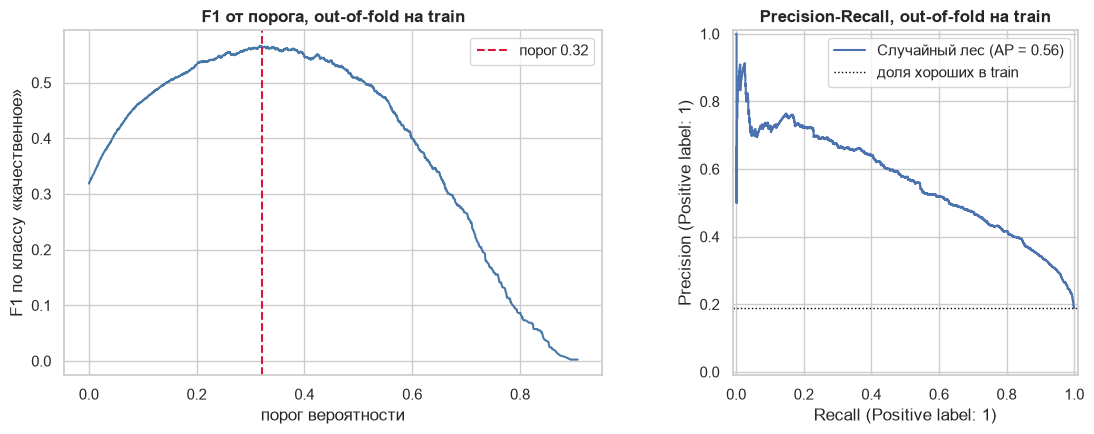

Порог с максимальным F1 на train: 0.321
F1 при этом пороге (OOF): 0.566


In [11]:
forest_oof = oof_probabilities["Случайный лес"]
precision, recall, thresholds = precision_recall_curve(yc_train, forest_oof)
f1_curve = 2 * precision * recall / (precision + recall + 1e-12)
best_index = int(np.argmax(f1_curve[:-1]))
best_threshold = float(thresholds[best_index])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(thresholds, f1_curve[:-1], color="#4878a8")
axes[0].axvline(best_threshold, color="crimson", linestyle="--", label=f"порог {best_threshold:.2f}")
axes[0].set_title("F1 от порога, out-of-fold на train")
axes[0].set_xlabel("порог вероятности")
axes[0].set_ylabel("F1 по классу «качественное»")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(yc_train, forest_oof, name="Случайный лес", ax=axes[1])
axes[1].axhline(yc_train.mean(), color="black", linestyle=":", linewidth=1, label="доля хороших в train")
axes[1].set_title("Precision-Recall, out-of-fold на train")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Порог с максимальным F1 на train: {best_threshold:.3f}")
print(f"F1 при этом пороге (OOF): {f1_curve[best_index]:.3f}")

Оценка регрессии идёт отдельно: те же данные, но цель — исходный балл 3–9. Сравниваем среднее,
линейную регрессию и лес по MAE и RMSE в 5-фолдовой кросс-валидации. MAE показывает типичную
ошибку в баллах, RMSE штрафует крупные промахи на редких 3 и 9.

In [12]:
regressors = {
    "Среднее (baseline)": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=False)),
            ("reg", DummyRegressor(strategy="mean")),
        ]
    ),
    "Линейная регрессия": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=True)),
            ("reg", LinearRegression()),
        ]
    ),
    "Случайный лес": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=False)),
            (
                "reg",
                RandomForestRegressor(
                    n_estimators=400,
                    min_samples_leaf=2,
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipeline in regressors.items():
    mae_scores = -cross_val_score(
        pipeline, X_train, yr_train, cv=kfold, scoring="neg_mean_absolute_error"
    )
    rmse_scores = -cross_val_score(
        pipeline, X_train, yr_train, cv=kfold, scoring="neg_root_mean_squared_error"
    )
    rows.append(
        {
            "модель": name,
            "MAE": mae_scores.mean(),
            "MAE std": mae_scores.std(),
            "RMSE": rmse_scores.mean(),
        }
    )

pd.DataFrame(rows).set_index("модель").round(3)

,MAE,MAE std,RMSE
модель,,,
Среднее (baseline),0.703,0.011,0.887
Линейная регрессия,0.570,0.007,0.741
Случайный лес,0.538,0.007,0.703


Средний балл как прогноз даёт MAE 0,70 — хуже этого уровня модель бесполезна. Лес снижает
ошибку до 0,54 в кросс-валидации, линейная регрессия до 0,57. Разница между ними небольшая,
но RMSE у леса ниже заметнее (0,70 против 0,74): крупные промахи случаются реже.
Классификацию и регрессию дальше ведём одним лесом, это упрощает сопровождение.

## 5. Оценка

Финальные модели обучаются на всём train и один раз проверяются на отложенных 20%.
Порог берётся из предыдущего раздела (0,32): он подобран на out-of-fold предсказаниях,
а не на тесте.

In [13]:
final_model = clone(classifiers["Случайный лес"]).fit(X_train, yc_train)
test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= best_threshold).astype(int)

print(
    classification_report(
        yc_test,
        test_prediction,
        target_names=["обычное", "качественное"],
        digits=3,
    )
)

              precision    recall  f1-score   support

     обычное      0.934     0.840     0.885       862
качественное      0.522     0.748     0.615       202

    accuracy                          0.822      1064
   macro avg      0.728     0.794     0.750      1064
weighted avg      0.856     0.822     0.833      1064



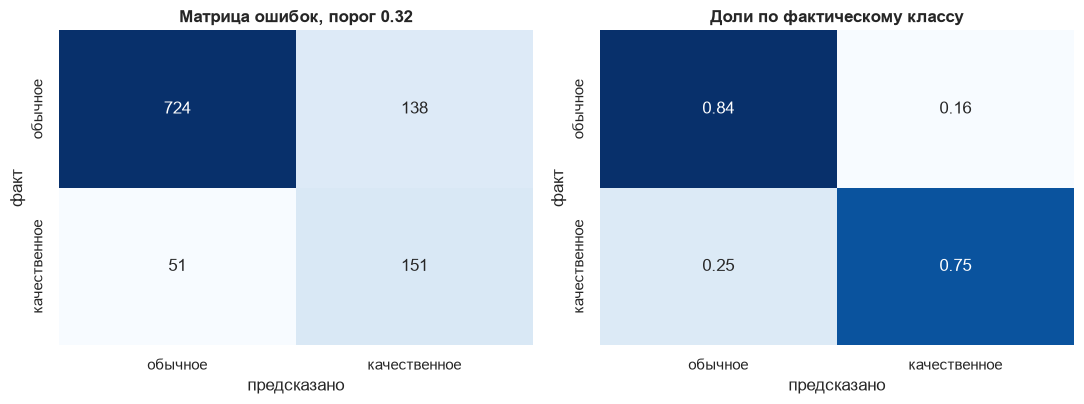

In [14]:
matrix = confusion_matrix(yc_test, test_prediction)
labels = ["обычное", "качественное"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0],
)
axes[0].set_title(f"Матрица ошибок, порог {best_threshold:.2f}")
axes[0].set_xlabel("предсказано")
axes[0].set_ylabel("факт")

sns.heatmap(
    matrix / matrix.sum(axis=1, keepdims=True),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1],
)
axes[1].set_title("Доли по фактическому классу")
axes[1].set_xlabel("предсказано")
axes[1].set_ylabel("факт")
plt.tight_layout()
plt.show()

Из 202 действительно качественных вин модель находит 151 (75%), отправляя на дегустацию ещё
138 обычных. Комиссия просматривает 289 партий вместо 202, то есть на 43% больше, но при
этом видит три четверти всего хорошего. Ровно этот обмен и был заложен в критерий recall.

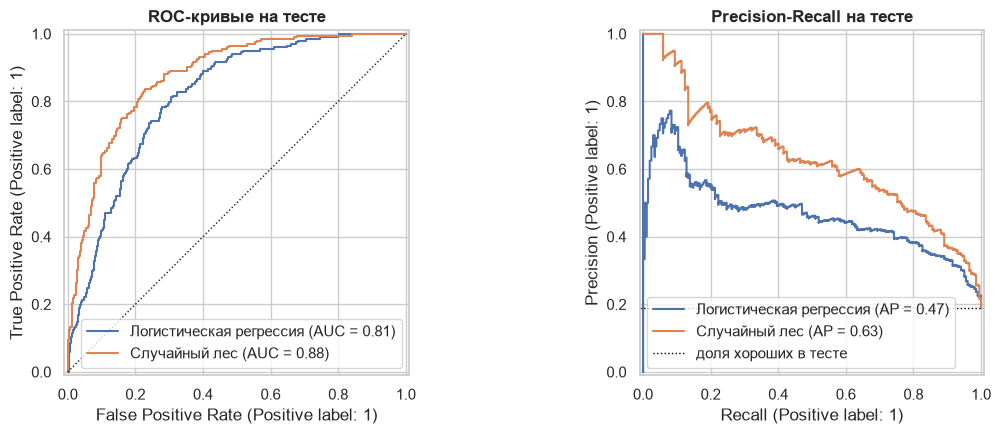

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pipeline in classifiers.items():
    if name.startswith("Dummy"):
        continue
    probabilities = clone(pipeline).fit(X_train, yc_train).predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(yc_test, probabilities, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(yc_test, probabilities, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k:", linewidth=1)
axes[0].set_title("ROC-кривые на тесте")
axes[1].axhline(yc_test.mean(), color="black", linestyle=":", linewidth=1, label="доля хороших в тесте")
axes[1].set_title("Precision-Recall на тесте")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

Что модель использует. Перестановочная важность на тесте отвечает на вопрос «насколько упадёт
ROC-AUC, если перемешать признак», и учитывает взаимодействия, в отличие от встроенной
важности деревьев.

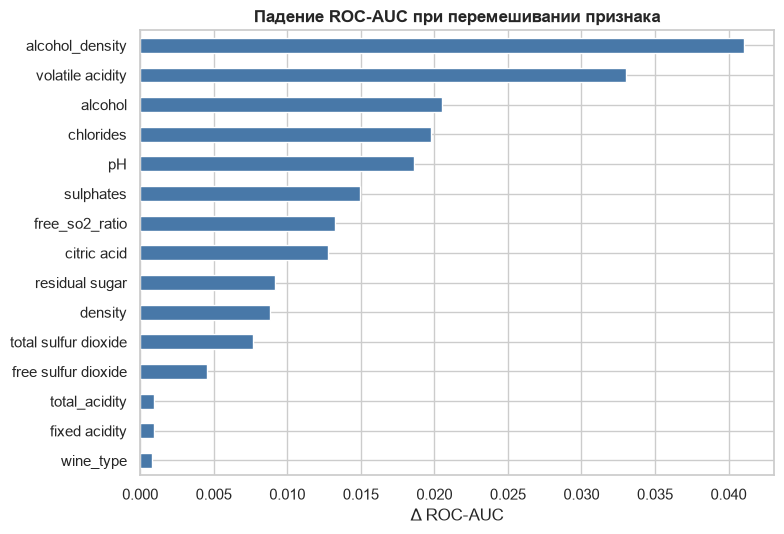

,Δ ROC-AUC
alcohol_density,0.041
volatile acidity,0.033
alcohol,0.020
chlorides,0.020
pH,0.019
sulphates,0.015
free_so2_ratio,0.013
citric acid,0.013
residual sugar,0.009
density,0.009


In [16]:
permutation = permutation_importance(
    final_model,
    X_test,
    yc_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
)
importance = pd.Series(permutation.importances_mean, index=feature_cols).sort_values()

axis = importance.plot.barh(figsize=(8, 5.5), color="#4878a8")
axis.set_title("Падение ROC-AUC при перемешивании признака")
axis.set_xlabel("Δ ROC-AUC")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(3).to_frame("Δ ROC-AUC")

Верхушка ожидаемая: отношение спирта к плотности, летучая кислотность, спирт и хлориды.
`wine_type` почти ничего не добавляет: после того как модель видит химию, тип вина не несёт
новой информации, хотя доли качественных у красных и белых разные. Это косвенный признак
того, что лес не выучил «ярлык типа» вместо содержательных признаков.

`total_acidity` и `fixed acidity` делят вклад: сумма дублирует один из компонентов, и важность
размазывается между ними. Однозначной интерпретации «этот признак важнее» здесь ждать нельзя,
нужны отдельные эксперименты с удалением признаков.

Проверим, не держится ли качество только на одном типе вина.

In [17]:
rows = []
for wine_type in ["red", "white"]:
    mask = (X_test["wine_type"] == wine_type).to_numpy()
    rows.append(
        {
            "тип": wine_type,
            "образцов": int(mask.sum()),
            "доля качественных": yc_test[mask].mean(),
            "F1": f1_score(yc_test[mask], test_prediction[mask]),
            "Recall": recall_score(yc_test[mask], test_prediction[mask]),
            "ROC-AUC": roc_auc_score(yc_test[mask], test_probability[mask]),
        }
    )

pd.DataFrame(rows).set_index("тип").round(3)

,образцов,доля качественных,F1,Recall,ROC-AUC
тип,,,,,
red,275,0.135,0.652,0.811,0.922
white,789,0.209,0.607,0.733,0.857


Красных вин в тесте втрое меньше (275 против 789), но разделяются они лучше: F1 0,652 против
0,607, ROC-AUC 0,922 против 0,857. Дело не в доле качественных, у белых она выше (20,9% против
13,5%), а в разбросе: белые сильнее расходятся по сахару и диоксиду серы, и граница 6/7
размывается. Это гипотеза; проверить её можно отдельной моделью внутри каждого типа.

Разбор ошибок: где именно они возникают.

In [18]:
error_table = pd.DataFrame(
    {
        "оценка комиссии": yr_test.to_numpy(),
        "факт": yc_test.to_numpy(),
        "прогноз": test_prediction,
        "вероятность": test_probability.round(3),
    }
)
error_table["ошибка"] = error_table["факт"] != error_table["прогноз"]

print(
    f"Ошибок: {error_table['ошибка'].sum()} из {len(error_table)} "
    f"({error_table['ошибка'].mean():.1%} теста)"
)
error_table.groupby("оценка комиссии").agg(
    образцов=("ошибка", "size"),
    ошибок=("ошибка", "sum"),
    доля=("ошибка", "mean"),
    средняя_вероятность=("вероятность", "mean"),
).round(3)

Ошибок: 189 из 1064 (17.8% теста)


,образцов,ошибок,доля,средняя_вероятность
оценка комиссии,,,,
3,5,0,0.000,0.067
4,38,2,0.053,0.086
5,328,11,0.034,0.085
6,491,125,0.255,0.221
7,177,50,0.282,0.450
8,25,1,0.040,0.574


175 ошибок из 189 приходятся на баллы 6 и 7: там ошибается четверть строк, тогда как на 3–5
и 8 — от 0 до 5%. Модель уверенно отделяет слабые вина, но «типичное» и «хорошее» по химии
пересекаются. Девяток в тесте не оказалось вовсе, поэтому про них по этой выборке сказать
нечего.

Это не дефект модели, а свойство данных: разница между «хорошим» и «типичным» вином на уровне
лабораторных показателей мала, а комиссия ставит балл ещё и по аромату и вкусу, которых
в таблице нет.

MAE на тесте: 0.500 | RMSE: 0.647 | критерий MAE <= 0,60


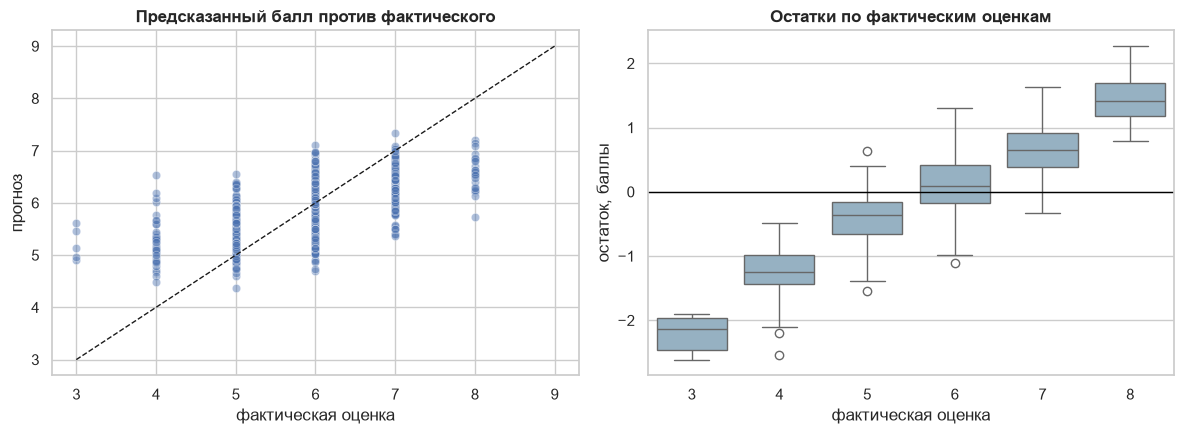

,образцов,средний_прогноз
факт,,
3,5,5.22
4,38,5.27
5,328,5.42
6,491,5.89
7,177,6.34
8,25,6.58


In [19]:
final_regressor = clone(regressors["Случайный лес"]).fit(X_train, yr_train)
test_score_prediction = final_regressor.predict(X_test)
holdout_mae = mean_absolute_error(yr_test, test_score_prediction)
holdout_rmse = mean_squared_error(yr_test, test_score_prediction) ** 0.5
print(f"MAE на тесте: {holdout_mae:.3f} | RMSE: {holdout_rmse:.3f} | критерий MAE <= 0,60")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=yr_test, y=test_score_prediction, alpha=0.45, ax=axes[0])
axes[0].plot([3, 9], [3, 9], "k--", linewidth=1)
axes[0].set_title("Предсказанный балл против фактического")
axes[0].set_xlabel("фактическая оценка")
axes[0].set_ylabel("прогноз")

sns.boxplot(x=yr_test.to_numpy(), y=(yr_test - test_score_prediction).to_numpy(), color="#8fb3c9", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Остатки по фактическим оценкам")
axes[1].set_xlabel("фактическая оценка")
axes[1].set_ylabel("остаток, баллы")
plt.tight_layout()
plt.show()

pd.DataFrame({"факт": yr_test.to_numpy(), "прогноз": test_score_prediction}).groupby("факт").agg(
    образцов=("прогноз", "size"),
    средний_прогноз=("прогноз", "mean"),
).round(2)

Прогноз стянут к центру: средние предсказания по группам лежат в коридоре 5,2–6,6 при факте
от 3 до 8. Лес усредняет листья, поэтому экстремальные баллы не выдаёт. Для сортировки партий
это приемлемо, для обещания «9 баллов» — нет. Если нужны точные крайние оценки, следует
пробовать порядковую регрессию или отдельную модель для хвостов.

In [20]:
test_metrics = {
    "F1 (quality >= 7)": f1_score(yc_test, test_prediction),
    "Precision (quality >= 7)": precision_score(yc_test, test_prediction),
    "Recall (quality >= 7)": recall_score(yc_test, test_prediction),
    "ROC-AUC": roc_auc_score(yc_test, test_probability),
    "PR-AUC": average_precision_score(yc_test, test_probability),
    "Accuracy": float((test_prediction == yc_test).mean()),
    "MAE регрессии": holdout_mae,
}

targets = {
    "F1 (quality >= 7)": (">=", 0.55),
    "Recall (quality >= 7)": (">=", 0.70),
    "ROC-AUC": (">=", 0.80),
    "MAE регрессии": ("<=", 0.60),
}
row_order = [
    "F1 (quality >= 7)",
    "Recall (quality >= 7)",
    "ROC-AUC",
    "MAE регрессии",
    "Precision (quality >= 7)",
    "PR-AUC",
    "Accuracy",
]

check = pd.DataFrame({"значение": pd.Series(test_metrics)}).reindex(row_order)


def check_target(name: str, value: float) -> str:
    if name not in targets:
        return "—"
    operator, limit = targets[name]
    passed = value >= limit if operator == ">=" else value <= limit
    return "да" if passed else "нет"


check["критерий"] = [
    f"{targets[name][0]} {targets[name][1]:.2f}" if name in targets else "—"
    for name in check.index
]
check["выполнен"] = [check_target(name, value) for name, value in check["значение"].items()]
check.round(3)

,значение,критерий,выполнен
F1 (quality >= 7),0.615,>= 0.55,да
Recall (quality >= 7),0.748,>= 0.70,да
ROC-AUC,0.876,>= 0.80,да
MAE регрессии,0.500,<= 0.60,да
Precision (quality >= 7),0.522,—,—
PR-AUC,0.629,—,—
Accuracy,0.822,—,—


Все четыре критерия из раздела 1 выполнены: F1 0,615 против порога 0,55, recall 0,748 против
0,70, ROC-AUC 0,876 против 0,80, MAE 0,500 против 0,60. Запаса по F1 меньше всего, и это
ожидаемо: класс редкий, а граница 6/7 размытая.

Accuracy 0,822 против 0,810 у константного ответа показывает, почему она не годится как
основной критерий: модель почти не выигрывает в доле правильных ответов, зато находит 75%
хороших вин против нуля у baseline.

## 6. Развёртывание

Модель сохраняется вместе с препроцессингом: `Pipeline` включает кодирование типа вина,
и на вход скорингу подаётся сырая таблица с теми же колонками, что у анализатора. Рядом
кладём JSON с метаданными: список признаков, порог, метрики на тесте, версия scikit-learn.
Без версии библиотеки артефакт через полгода может не открыться.

Файлы попадают в `models/`, который исключён из git: веса воспроизводятся запуском ноутбука,
а бинарники в репозитории быстро устаревают.

In [21]:
bundle = {
    "classifier": final_model,
    "regressor": final_regressor,
    "threshold": best_threshold,
}
model_path = MODEL_DIR / "wine_quality_rf.joblib"
joblib.dump(bundle, model_path, compress=3)

metadata = {
    "dataset": "UCI Wine Quality, red + white",
    "rows_after_cleaning": int(len(df)),
    "features": feature_cols,
    "threshold": round(best_threshold, 4),
    "holdout_metrics": {name: round(float(value), 4) for name, value in test_metrics.items()},
    "sklearn_version": sklearn.__version__,
    "trained_at": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
}
metadata_path = MODEL_DIR / "wine_quality_rf.metadata.json"
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Модель: {model_path.name}, {model_path.stat().st_size / 1024 / 1024:.1f} МБ")
print(metadata_path.read_text(encoding="utf-8"))

Модель: wine_quality_rf.joblib, 16.6 МБ
{
  "dataset": "UCI Wine Quality, red + white",
  "rows_after_cleaning": 5320,
  "features": [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "wine_type",
    "total_acidity",
    "free_so2_ratio",
    "alcohol_density"
  ],
  "threshold": 0.3212,
  "holdout_metrics": {
    "F1 (quality >= 7)": 0.6151,
    "Precision (quality >= 7)": 0.5225,
    "Recall (quality >= 7)": 0.7475,
    "ROC-AUC": 0.8756,
    "PR-AUC": 0.629,
    "Accuracy": 0.8224,
    "MAE регрессии": 0.5003
  },
  "sklearn_version": "1.9.1",
  "trained_at": "2026-11-23 10:43 UTC"
}


Скоринг партии: функция принимает таблицу в формате анализатора, возвращает вероятность
«качественного», ожидаемый балл и решение, отправлять ли партию на дегустацию. Сортировка
по вероятности — это и есть очередь для комиссии.

In [22]:
def score_wines(samples: pd.DataFrame) -> pd.DataFrame:
    """Считает вероятность quality >= 7 и ожидаемый балл для каждой партии."""
    missing = sorted(set(feature_cols) - set(samples.columns))
    if missing:
        raise ValueError(f"Не хватает признаков: {missing}")

    scored = samples.copy()
    scored["probability_good"] = final_model.predict_proba(scored[feature_cols])[:, 1]
    scored["predicted_score"] = final_regressor.predict(scored[feature_cols])
    scored["verdict"] = np.where(
        scored["probability_good"] >= best_threshold, "на дегустацию", "в общий поток"
    )
    return scored.sort_values("probability_good", ascending=False)


demo = X_test.head(5)
score_wines(demo)[
    ["wine_type", "alcohol", "volatile acidity", "probability_good", "predicted_score", "verdict"]
].round(3)

,wine_type,alcohol,volatile acidity,probability_good,predicted_score,verdict
371,red,11.0,0.24,0.520,6.372,на дегустацию
3776,white,10.2,0.25,0.092,5.856,в общий поток
556,red,9.4,0.54,0.036,5.545,в общий поток
2391,white,10.0,0.28,0.023,5.437,в общий поток
1203,red,9.9,0.64,0.004,5.129,в общий поток


Обслуживание модели:

- входной контроль: раз в неделю сравнивать распределения спирта, кислот и SO2 с обучающими
  (тест Колмогорова–Смирнова по каждому признаку), расхождение — повод переобучить;
- контроль качества: доля партий, которые комиссия признала хорошими среди отправленных моделью,
  должна оставаться около 52% precision; падение означает сдвиг либо в химии партий, либо
  в оценках комиссии;
- порог — параметр бизнеса, а не модели: если комиссия не успевает, порог поднимают и получают
  меньше ложных тревог за счёт пропущенных вин;
- переобучение — при накоплении новых партий (раз в сезон) и при смене хозяйства: набор
  из одного региона, перенос без проверки не гарантирован.

Чего в этой работе нет, но понадобится в промышленном запуске: мониторинга дрейфа, калибровки
вероятностей (лес с весами классов выдаёт смещённые вероятности), A/B-сравнения с текущим
порядком дегустации.

## 7. Выводы

Что получилось:

- данные очищены от 1177 полных дубликатов, осталось 5320 образцов;
- случайный лес на тесте: ROC-AUC 0,876, PR-AUC 0,629, F1 по классу «качественное» 0,615
  при пороге 0,32, recall 0,748;
- регрессия того же леса: MAE 0,500 балла, RMSE 0,647;
- все четыре критерия из раздела 1 выполнены; accuracy 0,82 против 0,81 у константного ответа
  показывает, почему accuracy здесь не показатель;
- главные признаки — отношение спирта к плотности, летучая кислотность, спирт; тип вина
  самостоятельного вклада почти не даёт;
- слабое место — граница между 6 и 7 баллами и редкие экстремальные оценки.

Что можно улучшить дальше, по убыванию ожидаемой пользы:

1. порядковая регрессия или две бинарные модели «>= 6» и «>= 8» вместо одной границы;
2. калибровка вероятностей (`CalibratedClassifierCV`), чтобы порог имел вероятностный смысл;
3. отбор признаков с проверкой на кросс-валидации: `fixed acidity` коррелирует с `total_acidity`
   на 0,99, один из двух признаков лишний;
4. внешняя проверка на данных другого хозяйства — без неё нельзя говорить о переносимости.

Для проекта курса (триаж инцидентов) из этой работы переносится не модель, а порядок действий:
критерии успеха до обучения, стратифицированное разделение, сравнение с константным baseline,
подбор порога на out-of-fold предсказаниях, разбор ошибок по подгруппам и сохранение метаданных
вместе с артефактом.

## Приложение. Воспроизводимость

Ноутбук не зависит от локальных файлов: при первом запуске он скачивает CSV с сервера UCI
и кэширует их в `data/raw`. Повторный запуск читает кэш и работает офлайн. Версии библиотек
на момент выполнения:

In [23]:
versions = pd.DataFrame(
    {
        "библиотека": ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "joblib"],
        "версия": [
            pd.__version__,
            np.__version__,
            sklearn.__version__,
            plt.matplotlib.__version__,
            sns.__version__,
            joblib.__version__,
        ],
    }
)
versions.set_index("библиотека").T

библиотека,pandas,numpy,scikit-learn,matplotlib,seaborn,joblib
версия,3.1.1,2.5.5,1.9.1,3.11.2,0.13.2,1.6.0
